# Step 2 — Explore the Data & Identify Prediction Targets
Examine the actual values and distributions to decide what our first ML models can predict.

In [4]:
from ai.src.data_loader import (
    load_career_pathway_data,
    load_skill_outcome_data
)

career_df = load_career_pathway_data()
outcome_df = load_skill_outcome_data()

print("Career:", career_df.shape)
print("Outcome:", outcome_df.shape)

Career: (4000, 17)
Outcome: (7000, 28)


## 2.2 — Inspect Key Categories

Identify the major career, course, demand, and outcome categories to guide later model targets.

In [5]:
print("Desired Careers:")
print(career_df["desired_career"].value_counts().head(10))

print("\nRecommended Courses:")
print(career_df["recommended_course"].value_counts().head(10))

print("\nLabour Market Demand:")
print(career_df["labour_market_demand_tier"].value_counts())

print("\nOutcome Paths:")
print(outcome_df["outcome_path"].value_counts())

Desired Careers:
desired_career
Automobile Technician          333
Electrician                    326
Mobile Repair Technician       296
Data Entry Operator            283
Two-Wheeler Mechanic           249
CNC Machine Operator           246
Accounts Assistant             239
Welder                         231
Web Developer (Entry-level)    204
Customer Support Associate     192
Name: count, dtype: int64

Recommended Courses:
recommended_course
Automobile Service Technician          333
Electrician - Domestic & Industrial    326
Mobile Phone Repair Technician         296
Data Entry Operator                    283
Two-Wheeler Mechanic                   249
CNC Machine Operator                   246
Tally & Basic Accounting               239
Welding Technician                     231
Web Development Basics                 204
Customer Support Associate (BPO)       192
Name: count, dtype: int64

Labour Market Demand:
labour_market_demand_tier
High      2122
Medium    1559
Low        319
N

- Interpretation: The dataset is dominated by high-demand trades, while formal employment is the largest outcome path.
- Conclusion: These categories are suitable for building our later career, demand, and outcome models.

## 2.3 — Analyze Numerical Features

Check the distributions of age, skill gaps, readiness, openings, income, and evidence levels.

In [6]:
print("CAREER PATHWAY")
display(
    career_df[
        ["age", "skill_gap_count", "readiness_pct", "estimated_openings_nearby"]
    ].describe()
)

print("\nSKILL OUTCOME")
display(
    outcome_df[
        ["age", "evidence_level", "starting_income_inr", "current_income_inr"]
    ].describe()
)

CAREER PATHWAY


,age,skill_gap_count,readiness_pct,estimated_openings_nearby
count,4000.000000,4000.000000,4000.000000,4000.000000
mean,23.432250,2.986250,25.343750,31.024250
std,4.020193,0.844831,21.120774,15.395809
min,17.000000,1.000000,0.000000,2.000000
25%,20.000000,2.000000,0.000000,19.000000
50%,23.000000,3.000000,25.000000,29.000000
75%,27.000000,4.000000,50.000000,44.000000
max,30.000000,4.000000,75.000000,60.000000



SKILL OUTCOME


,age,evidence_level,starting_income_inr,current_income_inr
count,7000.000000,7000.000000,2339.000000,3285.000000
mean,26.491714,1.158857,11001.229158,13194.328463
std,5.186306,1.527261,1719.289274,3904.854466
min,18.000000,0.000000,8000.000000,4013.000000
25%,22.000000,0.000000,9492.500000,10632.000000
50%,26.000000,0.000000,11032.000000,12740.000000
75%,31.000000,2.000000,12455.000000,15198.000000
max,35.000000,5.000000,13997.000000,24986.000000


- Interpretation: Career data shows an average readiness of 25.3% and about 3 skill gaps per trainee. Outcome data provides usable income/evidence information, with income missing where employment data is unavailable.

- Conclusion: The numeric fields provide useful features for readiness, placement, retention, and salary-related models.

## 2.4 — Analyze Retention Targets

Check the available 30/90/180/365-day retention data to determine which retention models are feasible.

In [7]:
retention_columns = [
    "retained_30_days",
    "retained_90_days",
    "retained_180_days",
    "retained_365_days"
]

for column in retention_columns:
    print("\n" + "=" * 40)
    print(column)
    print("=" * 40)
    print(outcome_df[column].value_counts(dropna=False))


retained_30_days
retained_30_days
True     2976
NaN      2579
False    1445
Name: count, dtype: int64

retained_90_days
retained_90_days
NaN      2579
True     2372
False    2049
Name: count, dtype: int64

retained_180_days
retained_180_days
False    2750
NaN      2579
True     1671
Name: count, dtype: int64

retained_365_days
retained_365_days
False    3441
NaN      2579
True      980
Name: count, dtype: int64


- Interpretation: All four retention periods have substantial usable records; 2,579 rows are missing across each period, so those rows need careful handling rather than treating them as False.

- Conclusion: We can build separate 30/90/180/365-day retention prediction models.

## 2.5 — Analyze Outcome & Evidence Distribution

Check placement outcomes and evidence levels to prepare for placement prediction and the claimed-vs-evidence-backed placement USP.

In [8]:
print("Outcome Path:")
print(outcome_df["outcome_path"].value_counts())

print("\nEvidence Level:")
print(outcome_df["evidence_level"].value_counts().sort_index())

print("\nEvidence Meaning:")
print(
    outcome_df[
        ["evidence_level", "evidence_level_meaning"]
    ].drop_duplicates().sort_values("evidence_level")
)

Outcome Path:
outcome_path
formal_employment     2339
not_certified         1472
unemployed_seeking    1136
unreachable           1107
self_employment        946
Name: count, dtype: int64

Evidence Level:
evidence_level
0    3583
1    1298
2     716
3     593
4     447
5     363
Name: count, dtype: int64

Evidence Meaning:
    evidence_level            evidence_level_meaning
2                0                     No update yet
0                1            Self-reported employed
9                2                 Document uploaded
3                3        Employer confirmed joining
24               4  Retention confirmed at follow-up
8                5            Independently verified


- Interpretation: Formal employment is the largest outcome group, while evidence levels range from 0 (no update) to 5 (independently verified).

- Conclusion: The dataset supports both placement/outcome analysis and the evidence-backed placement USP.

## 2.6 — Analyze Skill-Gap Data

Understand the skill-gap fields so we can design the skill gap analysis and skill recommendation component.

In [9]:
print("Skill Gap Count:")
print(career_df["skill_gap_count"].value_counts().sort_index())

print("\nMissing Skills:")
print(career_df["missing_skills"].value_counts().head(15))

print("\nExisting Skills:")
print(career_df["existing_skills"].value_counts().head(15))

Skill Gap Count:
skill_gap_count
1     136
2    1047
3    1553
4    1264
Name: count, dtype: int64

Missing Skills:
missing_skills
Soldering; Component diagnosis; Customer handling; Steady hands                  100
Engine diagnostics; Tool handling; Safety protocols; Problem solving              97
Machine operation; Blueprint reading; Precision measurement; Safety protocols     95
Basic wiring; Circuit testing; Safety protocols; Tool handling                    94
Typing speed; Basic computer literacy; Attention to detail; MS Excel              91
Welding technique; Safety protocols; Tool handling; Blueprint reading             87
Basic computer literacy; Logical thinking; HTML/CSS basics; English reading       87
Engine diagnostics; Tool handling; Safety protocols                               79
Basic numeracy; Tally software; Record keeping; Communication                     72
Stitching; Pattern making; Measurement; Creativity                                71
Engine diagnostics;

- Interpretation: Most trainees have 2–4 missing skills, with skill combinations clearly represented in the data.

- Conclusion: We can build a skill-gap and skill-recommendation component from these fields.

## 2.7 — Analyze Skill Demand by District & Trade

Establish the baseline for our USP by comparing labour-market demand across districts and careers.

In [10]:
demand_by_district = (
    career_df
    .groupby(["district", "labour_market_demand_tier"])
    .size()
    .unstack(fill_value=0)
)

print("Demand by District:")
display(demand_by_district)

print("\nAverage Openings by District:")
display(
    career_df.groupby("district")["estimated_openings_nearby"]
    .mean()
    .sort_values(ascending=False)
    .head(15)
)

Demand by District:


labour_market_demand_tier,High,Low,Medium
district,,,
Ahmednagar,155,23,96
Akola,135,22,97
Amravati,103,4,64
Beed,83,12,73
Chhatrapati Sambhajinagar,62,7,44
Dhule,106,12,73
Jalgaon,106,19,77
Kolhapur,102,14,68
Latur,127,17,76



Average Openings by District:


district
Mumbai Suburban              33.635838
Amravati                     33.175439
Dhule                        32.486911
Ahmednagar                   32.233577
Latur                        31.940909
Kolhapur                     31.690217
Nanded                       31.531120
Yavatmal                     31.382775
Chhatrapati Sambhajinagar    31.318584
Mumbai City                  31.219895
Sangli                       30.938095
Akola                        30.795276
Satara                       30.562162
Pune                         30.481675
Jalgaon                      29.846535
Name: estimated_openings_nearby, dtype: float64

- Interpretation: Mumbai Suburban has the highest average nearby openings (33.64), followed by Amravati (33.18) and Dhule (32.49).

- Conclusion: District-level opening variation is useful for our demand comparison and Maharashtra map visualization.

## 2.8 — Skill Demand Frequency

Break the combined skill strings into individual skills and find the most frequently required/missing skills.

In [11]:
from collections import Counter

def count_skills(series):
    skills = []

    for value in series.dropna():
        skills.extend(
            skill.strip()
            for skill in str(value).split(";")
            if skill.strip()
        )

    return Counter(skills)


required_skills = count_skills(career_df["job_required_skills"])
missing_skills = count_skills(career_df["missing_skills"])
existing_skills = count_skills(career_df["existing_skills"])

print("Top Required Skills:")
print(required_skills.most_common(15))

print("\nTop Missing Skills:")
print(missing_skills.most_common(15))

print("\nTop Existing Skills:")
print(existing_skills.most_common(15))

Top Required Skills:
[('Safety protocols', 1755), ('Tool handling', 1509), ('Communication', 1061), ('Customer handling', 720), ('Basic computer literacy', 679), ('Basic wiring', 603), ('Engine diagnostics', 582), ('Problem solving', 582), ('Hygiene practices', 533), ('Blueprint reading', 477), ('Circuit testing', 477), ('English reading', 396), ('Soldering', 296), ('Component diagnosis', 296), ('Steady hands', 296)]

Top Missing Skills:
[('Safety protocols', 1213), ('Tool handling', 1025), ('Communication', 698), ('Customer handling', 480), ('Basic wiring', 477), ('Basic computer literacy', 461), ('Engine diagnostics', 457), ('Blueprint reading', 409), ('Hygiene practices', 400), ('Problem solving', 397), ('Circuit testing', 385), ('English reading', 284), ('Steady hands', 241), ('Soldering', 238), ('Attention to detail', 237)]

Top Existing Skills:
[('Safety protocols', 856), ('Tool handling', 845), ('Communication', 768), ('Customer handling', 738), ('Basic computer literacy', 694),

- Interpretation: Safety protocols, tool handling, and communication are the most frequently required and missing skills, showing clear training gaps.

- Conclusion: These skill frequencies can support skill-gap prioritization and future skill recommendations.

## 2.9 — Analyze Training vs Industry Skills

Compare job-required skills with skills actually present in training/trainee profiles to support the training-center alignment USP.

In [12]:
required = set(required_skills)
existing = set(existing_skills)

covered_skills = required & existing
uncovered_skills = required - existing

print("Total industry-required skills:", len(required))
print("Skills covered in trainee data:", len(covered_skills))
print("Skills not represented in existing skills:", len(uncovered_skills))

print("\nCovered Skills:")
print(sorted(covered_skills))

print("\nUncovered Skills:")
print(sorted(uncovered_skills))

Total industry-required skills: 45
Skills covered in trainee data: 45
Skills not represented in existing skills: 0

Covered Skills:
['Attention to detail', 'Basic billing', 'Basic computer literacy', 'Basic numeracy', 'Basic wiring', 'Blueprint reading', 'Circuit testing', 'Communication', 'Component diagnosis', 'Creativity', 'Customer handling', 'Empathy', 'Engine diagnostics', 'English reading', 'HTML/CSS basics', 'Hygiene practices', 'Inventory basics', 'Local travel willingness', 'Logical thinking', 'MS Excel', 'Machine operation', 'Measurement', 'Patience', 'Patient care basics', 'Pattern making', 'Persuasion', 'Pipefitting', 'Precision measurement', 'Problem solving', 'Product knowledge', 'Recipe following', 'Record keeping', 'Safety protocols', 'Soldering', 'Steady hands', 'Stitching', 'Styling technique', 'Tally software', 'Target orientation', 'Teamwork', 'Time management', 'Tool handling', 'Typing speed', 'Welding technique', 'Working at heights']

Uncovered Skills:
[]


- Interpretation: All 45 industry-required skills are represented in the existing-skill data, so this simple comparison cannot identify uncovered skills.

- Conclusion: For a meaningful training-vs-industry gap, we need to compare skills per trainee/course/trade, not across the entire dataset.

## 2.10 — Course/Trade Skill Alignment

Compare required vs missing skills within each career/trade to identify where training alignment is weakest.

In [15]:
import pandas as pd

def split_skills(value):
    if pd.isna(value):
        return set()
    return {skill.strip() for skill in str(value).split(";") if skill.strip()}


alignment_results = []

for career, group in career_df.groupby("desired_career"):

    required = set()
    missing = set()

    for value in group["job_required_skills"]:
        required.update(split_skills(value))

    for value in group["missing_skills"]:
        missing.update(split_skills(value))

    alignment_pct = (
        (len(required - missing) / len(required)) * 100
        if required else 0
    )

    alignment_results.append({
        "career": career,
        "required_skills": len(required),
        "missing_skills": len(missing),
        "alignment_pct": round(alignment_pct, 2)
    })

alignment_df = pd.DataFrame(alignment_results)

display(
    alignment_df.sort_values("alignment_pct").head(15)
)

,career,required_skills,missing_skills,alignment_pct
0,Accounts Assistant,4,4,0.0
1,Automobile Technician,4,4,0.0
2,Baker,4,4,0.0
3,Beautician,4,4,0.0
4,CNC Machine Operator,4,4,0.0
5,Customer Support Associate,4,4,0.0
6,Data Entry Operator,4,4,0.0
7,Electrical Wireman,4,4,0.0
8,Electrician,4,4,0.0
9,Field Sales Executive,4,4,0.0


- Interpretation: The result shows 0% alignment for every career, because all 4 required skills are also appearing in the missing-skills field. This indicates our current calculation is not a valid measure of training alignment.

- Conclusion: We should not use this metric/model. Next we'll calculate alignment using existing skills vs required skills for each trainee/trade.

## 2.11 — Trainee-Level Skill Alignment

- Calculate how well each trainee's existing skills cover the skills required for their desired career.
- Skill-set intersection / coverage percentage

In [16]:
def calculate_alignment(row):
    required = split_skills(row["job_required_skills"])
    existing = split_skills(row["existing_skills"])

    if not required:
        return 0

    return round(len(required & existing) / len(required) * 100, 2)


career_df["skill_alignment_pct"] = career_df.apply(
    calculate_alignment,
    axis=1
)

display(
    career_df[
        [
            "desired_career",
            "skill_alignment_pct",
            "skill_gap_count",
            "readiness_pct"
        ]
    ].head(20)
)

print("\nAverage Alignment by Career:")
display(
    career_df.groupby("desired_career")["skill_alignment_pct"]
    .mean()
    .sort_values()
    .round(2)
)

,desired_career,skill_alignment_pct,skill_gap_count,readiness_pct
0,Field Sales Executive,25.0,3,25
1,Accounts Assistant,50.0,2,50
2,Welder,0.0,4,0
3,Accounts Assistant,50.0,2,50
4,CNC Machine Operator,0.0,4,0
5,Welder,75.0,1,75
6,Solar Panel Installer,25.0,3,25
7,Two-Wheeler Mechanic,25.0,3,25
8,Baker,0.0,4,0
9,Accounts Assistant,50.0,2,50



Average Alignment by Career:


desired_career
Web Developer (Entry-level)      21.57
CNC Machine Operator             22.05
Tailor / Fashion Designer        22.43
Welder                           22.51
Mobile Repair Technician         23.73
Retail Sales Associate           24.13
Plumber                          24.19
Field Sales Executive            24.44
Data Entry Operator              24.65
Nursing Assistant                24.83
Electrical Wireman               25.00
Accounts Assistant               25.31
Beautician                       25.83
Electrician                      26.30
Solar Panel Installer            26.39
Baker                            26.89
Automobile Technician            27.48
Customer Support Associate       27.99
Two-Wheeler Mechanic             29.32
Food & Beverage Service Staff    32.30
Name: skill_alignment_pct, dtype: float64

- Interpretation: Average skill alignment varies by career from 21.57% (Web Developer) to 32.30% (Food & Beverage Service Staff).

- Conclusion: Career-wise alignment differences are meaningful and can support training-center recommendations.

## 2.12 — Training Readiness vs Skill Alignment

- Check whether our calculated skill alignment agrees with the dataset's existing readiness percentage.
- Correlation analysis

In [17]:
print(
    career_df[
        ["skill_alignment_pct", "readiness_pct"]
    ].corr()
)

print("\nAverage values:")
display(
    career_df[
        ["skill_alignment_pct", "readiness_pct"]
    ].mean().round(2)
)

                     skill_alignment_pct  readiness_pct
skill_alignment_pct                  1.0            1.0
readiness_pct                        1.0            1.0

Average values:


skill_alignment_pct    25.34
readiness_pct          25.34
dtype: float64

- Interpretation: Skill alignment and readiness are exactly identical in this dataset (correlation = 1.0, both average 25.34%).

- Conclusion: readiness_pct appears to be directly derived from the skill-alignment calculation, so we should avoid using both as independent ML features to prevent redundancy/data leakage.

## 2.13 — Identify ML Target Candidates

- Check which outcome variables have enough valid data to become reliable ML prediction targets.
- Target feasibility analysis

In [18]:
targets = [
    "outcome_path",
    "retained_30_days",
    "retained_90_days",
    "retained_180_days",
    "retained_365_days",
    "starting_income_inr",
    "current_income_inr"
]

target_summary = []

for target in targets:
    valid = outcome_df[target].notna().sum()
    missing = outcome_df[target].isna().sum()

    target_summary.append({
        "target": target,
        "valid_records": valid,
        "missing_records": missing,
        "usable_pct": round(valid / len(outcome_df) * 100, 2)
    })

target_summary_df = pd.DataFrame(target_summary)

display(target_summary_df)

,target,valid_records,missing_records,usable_pct
0,outcome_path,7000,0,100.00
1,retained_30_days,4421,2579,63.16
2,retained_90_days,4421,2579,63.16
3,retained_180_days,4421,2579,63.16
4,retained_365_days,4421,2579,63.16
5,starting_income_inr,2339,4661,33.41
6,current_income_inr,3285,3715,46.93


- Interpretation: outcome_path has 100% usable data; each retention target has 4,421 records (63.16%), while income targets have fewer usable records.

- Conclusion: Outcome and retention prediction are strongly feasible; salary prediction will have a smaller training set.

## 2.14 — Define the First Prediction Target

- Identify the exact target for our first ML model: placement outcome prediction.

- Algorithm: Classification — algorithm will be chosen after feature analysis.

In [19]:
print("Outcome Path Distribution:")
print(outcome_df["outcome_path"].value_counts())

print("\nUnique Outcome Paths:")
print(outcome_df["outcome_path"].unique())

Outcome Path Distribution:
outcome_path
formal_employment     2339
not_certified         1472
unemployed_seeking    1136
unreachable           1107
self_employment        946
Name: count, dtype: int64

Unique Outcome Paths:
<StringArray>
[ 'formal_employment',        'unreachable',    'self_employment',
      'not_certified', 'unemployed_seeking']
Length: 5, dtype: str


- Interpretation: The dataset has 5 outcome categories, with formal_employment the largest group (2,339 records).

- Conclusion: We can model placement/outcome prediction as a multiclass classification problem.

## 2.15 — Create Placement Target

- Convert the outcome categories into a binary placed target for placement-probability prediction.
- Algorithm: Binary classification target preparation.

In [20]:
placed_paths = [
    "formal_employment",
    "self_employment"
]

outcome_df["placed"] = outcome_df["outcome_path"].isin(placed_paths)

print(outcome_df["placed"].value_counts())

print("\nPlacement percentage:")
print((outcome_df["placed"].mean() * 100).round(2), "%")

placed
False    3715
True     3285
Name: count, dtype: int64

Placement percentage:
46.93 %


- Interpretation: 3,285 trainees (46.93%) are classified as placed, using formal or self-employment as the positive outcome.

- Conclusion: The binary placement target is reasonably balanced and suitable for classification.

## 2.16 — Check Placement Class Balance

- Check whether the placed target is balanced enough for classification.

- Algorithm: Class-balance analysis.

In [21]:
print("Placement counts:")
print(outcome_df["placed"].value_counts())

print("\nPlacement percentages:")
print(
    (outcome_df["placed"].value_counts(normalize=True) * 100)
    .round(2)
)

Placement counts:
placed
False    3715
True     3285
Name: count, dtype: int64

Placement percentages:
placed
False    53.07
True     46.93
Name: proportion, dtype: float64


- Interpretation: The target is well balanced: 46.93% placed and 53.07% not placed.

- Conclusion: No major class-imbalance correction is needed for the first placement model.

## 2.17 — Check Feature Relationships with Placement

- Identify which available features are most related to the placed target before selecting model inputs.

- Algorithm: Group comparison + correlation analysis.

In [22]:
# Numeric feature relationships
numeric_features = [
    "age",
    "evidence_level",
    "starting_income_inr",
    "current_income_inr"
]

print("Average values by placement status:\n")

display(
    outcome_df.groupby("placed")[numeric_features]
    .mean(numeric_only=True)
    .round(2)
)

Average values by placement status:



,age,evidence_level,starting_income_inr,current_income_inr
placed,,,,
False,26.53,0.09,NaN,NaN
True,26.45,2.37,11001.23,13194.33


- Interpretation: evidence_level strongly separates placed vs. not placed trainees, while age shows almost no difference. Income is available only for placed trainees, so it cannot be used as a placement predictor.

- Conclusion: We should investigate training/course, district, certification, and other pre-placement features next, while excluding post-placement fields to avoid data leakage.

## 2.18 — Check Pre-Placement Features

- Identify which API-available, pre-placement fields show meaningful differences in placement rate.

- Algorithm: Group-wise placement-rate analysis.

In [23]:
categorical_features = [
    "district",
    "course_trade",
    "training_provider",
    "gender",
    "completed_training"
]

for feature in categorical_features:
    print("\n" + "=" * 60)
    print(feature)

    placement_rate = (
        outcome_df.groupby(feature)["placed"]
        .mean()
        .mul(100)
        .sort_values(ascending=False)
    )

    print(placement_rate.head(10).round(2))


district
district
Nagpur        53.10
Ahmednagar    52.10
Akola         51.84
Dhule         51.21
Amravati      49.68
Thane         48.99
Yavatmal      47.87
Nashik        47.63
Solapur       46.81
Jalgaon       46.65
Name: placed, dtype: float64

course_trade
course_trade
Nursing Assistant / Home Health Aide    51.55
Food & Beverage Service                 50.78
Electrician - Domestic & Industrial     50.67
Bakery & Confectionery                  50.63
Customer Support Associate (BPO)        49.06
Tailoring & Fashion Design              49.03
Tally & Basic Accounting                48.70
Two-Wheeler Mechanic                    48.46
CNC Machine Operator                    48.13
Automobile Service Technician           47.64
Name: placed, dtype: float64

training_provider
training_provider
Konda, Gade and Shere Skill Center      57.76
Loke, Bora and Garg Skill Center        53.47
Iyer, Muni and Rastogi Skill Center     53.27
Lall, Tella and Gokhale Skill Center    52.94
Murty, Kala and

- Interpretation: District, course, and training provider show meaningful placement-rate variation; completed_training is especially important, while gender differences are small.

- Conclusion: These are strong pre-placement candidate features, but we should further check for leakage and API alignment before finalizing them.

## 2.19 — Finalize Placement Model Features

- Select only pre-placement, API-compatible features for the first placement-probability model and avoid data leakage.

- Algorithm: Feature selection by domain rules + leakage check.

In [24]:
candidate_features = [
    "district",
    "course_trade",
    "training_provider",
    "gender",
    "age",
    "completed_training"
]

print("Selected features:")
for feature in candidate_features:
    print("-", feature)

print("\nTarget:")
print("- placed")

Selected features:
- district
- course_trade
- training_provider
- gender
- age
- completed_training

Target:
- placed


## FINAL
- Interpretation: The selected features are clearly defined, with placed as the prediction target.

- Conclusion: Step 2 is complete. We can now move to Step 3 — Preprocessing & feature encoding for the placement model.

# Step 3 — Preprocess Placement Model Data

Prepare the selected pre-placement features for machine learning while keeping the original API field names.

<b>Algorithm: One-hot encoding for categorical features + numeric passthrough.</b>

## 3.1 — Create the Preprocessing Pipeline

Build a reusable preprocessing pipeline that can be saved and reused during testing/production.

In [27]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# ============================================================
# PLACEMENT PREDICTION MODEL
# ============================================================

# FEATURES (inputs available before placement)
candidate_features = [
    "district",             # trainee location
    "course_trade",         # training/course completed
    "training_provider",    # training centre
    "gender",               # trainee demographic
    "age",                  # trainee age
    "completed_training"    # whether training was completed
]

# TARGET (what the model predicts)
# True  -> placed
# False -> not placed
target = "placed"

categorical_features = [
    "district",
    "course_trade",
    "training_provider",
    "gender"
]

numeric_features = [
    "age",
    "completed_training"
]

# Prepare X and y
X = outcome_df[candidate_features].copy()
y = outcome_df[target].astype(int)

# Preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numeric",
            "passthrough",
            numeric_features
        )
    ]
)

print("PLACEMENT MODEL")
print("\nFeatures:")
for feature in candidate_features:
    print(f"- {feature}")

print(f"\nTarget: {target}")

print("\nInput shape:", X.shape)
print("Target shape:", y.shape)
print("Placed:", y.sum())
print("Not placed:", (y == 0).sum())

PLACEMENT MODEL

Features:
- district
- course_trade
- training_provider
- gender
- age
- completed_training

Target: placed

Input shape: (7000, 6)
Target shape: (7000,)
Placed: 3285
Not placed: 3715


- Interpretation: The preprocessing input contains 7,000 records and 6 selected features, with 3,285 placed and 3,715 not placed.

- Conclusion: The data is ready for train/test splitting and model training.


formal_employment → 1 (placed)
self_employment → 0
unemployed_seeking → 0
unreachable → 0
not_certified → 0

- This makes the model specifically predict formal employment placement, rather than mixing placement with other livelihood outcomes.
- We'll keep self-employment as a separate outcome category for later livelihood/outcome intelligence.

## 3.2 — Split Training & Testing Data

- Divide the data into training and testing sets so we can evaluate the placement model on unseen trainees.
- Algorithm: Stratified train-test split.

In [28]:
from sklearn.model_selection import train_test_split

# Placement target:
# 1 = formal employment
# 0 = all other outcome paths

y = (outcome_df["outcome_path"] == "formal_employment").astype(int)
X = outcome_df[candidate_features].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training samples: 5600
Testing samples: 1400

Training target distribution:
outcome_path
0    3729
1    1871
Name: count, dtype: int64

Testing target distribution:
outcome_path
0    932
1    468
Name: count, dtype: int64


- Interpretation: Data is split into 5,600 training and 1,400 testing records, with the class proportions preserved.

- Conclusion: The split is ready for training and evaluating the formal-placement model.

## 3.3 — Train Baseline Placement Model

- Add feature scaling for numeric inputs before retraining the Logistic Regression model.
- Train our first formal-employment probability model using the finalized features.


- Algorithm: StandardScaler + OneHotEncoder + Logistic Regression — a simple, interpretable classification baseline.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

categorical_features = [
    "district",
    "course_trade",
    "training_provider",
    "gender"
]

numeric_features = [
    "age",
    "completed_training"
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numeric",
            StandardScaler(),
            numeric_features
        )
    ]
)

placement_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ]
)

placement_model.fit(X_train, y_train)

print("Scaled placement model training completed.")

Placement model training completed.


- Interpretation: The Logistic Regression placement model trained successfully without errors.

- Conclusion: The baseline model is ready for evaluation on unseen test data.

## 3.4 — Evaluate Placement Model

- Measure how well the trained model predicts formal employment on unseen test data.

- Algorithm: Accuracy + Precision + Recall + F1-score + ROC-AUC.

In [34]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Predictions
y_pred = placement_model.predict(X_test)
y_prob = placement_model.predict_proba(X_test)[:, 1]

# Evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print("Placement Model Evaluation")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")

Placement Model Evaluation
Accuracy : 0.6507
Precision: 0.4444
Recall   : 0.1795
F1 Score : 0.2557
ROC-AUC  : 0.6586


- Interpretation: The baseline model has ROC-AUC 0.658, but recall is low (0.175), so it misses many formally placed trainees.

Scaling made almost no difference: ROC-AUC improved slightly from 0.6579 → 0.6586, while F1 improved from 0.2519 → 0.2557.


- Conclusion: The baseline is not strong enough yet; we should improve the feature set/model before saving it for production.

Scaling is correctly implemented, but feature quality is currently the bigger limitation. Next we'll examine better pre-placement features before changing algorithms.

## 3.4 — Add Valid Pre-Placement Features

- Add useful information available before placement without introducing post-placement leakage.

- Algorithm: Feature engineering — date-derived training timing.

In [36]:
# Work on a copy
X = outcome_df[candidate_features].copy()

# Convert dates
enrolment_date = pd.to_datetime(
    outcome_df["enrolment_date"],
    errors="coerce"
)

certification_date = pd.to_datetime(
    outcome_df["certification_date"],
    errors="coerce"
)

# Training duration until certification
X["training_duration_days"] = (
    certification_date - enrolment_date
).dt.days

# For trainees without certification, keep the value missing.
print("Training duration summary:")
print(X["training_duration_days"].describe())

print("\nMissing training duration:")
print(X["training_duration_days"].isna().sum())

Training duration summary:
count    5528.000000
mean      104.252713
std        43.770699
min        30.000000
25%        66.000000
50%       104.000000
75%       142.000000
max       180.000000
Name: training_duration_days, dtype: float64

Missing training duration:
1472


- Interpretation: Certification data gives a usable training duration for 5,528 trainees, while 1,472 have no certification date.

- Conclusion: Training duration can be a useful feature, but we should handle the missing values carefully before adding it to the model.

## 3.5 — Add Certification & Training Duration Features

- Add certified and training_duration_days as useful post-training/pre-placement features, while preserving missing-information indicators.

- Algorithm: Feature engineering + median imputation.

In [37]:
import numpy as np

X = outcome_df[candidate_features].copy()

# Certification status
X["certified"] = outcome_df["certification_date"].notna().astype(int)

# Training duration
X["training_duration_days"] = (
    pd.to_datetime(outcome_df["certification_date"], errors="coerce")
    - pd.to_datetime(outcome_df["enrolment_date"], errors="coerce")
).dt.days

# Missing-duration indicator
X["training_duration_missing"] = (
    X["training_duration_days"].isna().astype(int)
)

# Median value for model input
median_duration = X["training_duration_days"].median()

X["training_duration_days"] = (
    X["training_duration_days"].fillna(median_duration)
)

print("Certified:")
print(X["certified"].value_counts())

print("\nTraining duration:")
print(X["training_duration_days"].describe())

print("\nMissing duration indicator:")
print(X["training_duration_missing"].value_counts())

Certified:
certified
1    5528
0    1472
Name: count, dtype: int64

Training duration:
count    7000.000000
mean      104.199571
std        38.896609
min        30.000000
25%        75.750000
50%       104.000000
75%       132.000000
max       180.000000
Name: training_duration_days, dtype: float64

Missing duration indicator:
training_duration_missing
0    5528
1    1472
Name: count, dtype: int64


- Interpretation: 5,528 trainees are certified; the remaining 1,472 have no certification date. We preserved this information with a missing-duration indicator.

- Conclusion: These features are ready to test in the placement model.

## 3.6 — Rebuild Train/Test Data with New Features

- Add the new certification and training-duration features to the train/test datasets before retraining.

- Algorithm: Feature engineering + stratified train/test split.

In [38]:
from sklearn.model_selection import train_test_split

# Features for placement prediction
model_features = [
    "district",
    "course_trade",
    "training_provider",
    "gender",
    "age",
    "completed_training",
    "certified",
    "training_duration_days",
    "training_duration_missing"
]

# Input features and target
X = X[model_features].copy()

# 1 = formal employment, 0 = all other outcomes
y = (
    outcome_df["outcome_path"] == "formal_employment"
).astype(int)

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training samples: 5600
Testing samples: 1400

Training target distribution:
outcome_path
0    3729
1    1871
Name: count, dtype: int64

Testing target distribution:
outcome_path
0    932
1    468
Name: count, dtype: int64


- Interpretation: The train/test split remains 5,600 / 1,400, with the placement class distribution preserved.

- Conclusion: The updated feature set is ready for model training.

## 3.7 — Train Updated Placement Model

- Train Logistic Regression using the expanded pre-placement feature set.

- Algorithm: Logistic Regression with one-hot encoding + standard scaling.

In [39]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

categorical_features = [
    "district",
    "course_trade",
    "training_provider",
    "gender"
]

numeric_features = [
    "age",
    "completed_training",
    "certified",
    "training_duration_days",
    "training_duration_missing"
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numeric",
            StandardScaler(),
            numeric_features
        )
    ]
)

placement_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ]
)

placement_model.fit(X_train, y_train)

print("Updated placement model trained successfully.")

Updated placement model trained successfully.


- Interpretation: The updated Logistic Regression model trained successfully with the expanded feature set.

- Conclusion: Next we evaluate it against the earlier baseline to see whether the new features improved performance.

## 3.8 — Evaluate Updated Placement Model

- Measure whether the added certification and training-duration features improved placement prediction.

- Algorithm: Accuracy + Precision + Recall + F1-score + ROC-AUC.

In [40]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

y_pred = placement_model.predict(X_test)
y_prob = placement_model.predict_proba(X_test)[:, 1]

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print("Updated Placement Model Evaluation")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")

Updated Placement Model Evaluation
Accuracy : 0.6529
Precision: 0.4536
Recall   : 0.1880
F1 Score : 0.2659
ROC-AUC  : 0.6582


## 3.9 — Train Random Forest Model

- Test a nonlinear model to see whether it captures relationships Logistic Regression missed.

- Algorithm: Random Forest Classifier — ensemble of decision trees.

In [41]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=300,
            max_depth=10,
            min_samples_split=10,
            min_samples_leaf=5,
            random_state=42,
            n_jobs=-1,
            class_weight="balanced"
        ))
    ]
)

random_forest_model.fit(X_train, y_train)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


## 3.10 — Evaluate Random Forest

- Measure Random Forest performance and compare it with our Logistic Regression baseline.

- Algorithm: Accuracy + Precision + Recall + F1-score + ROC-AUC.

In [42]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

y_pred_rf = random_forest_model.predict(X_test)
y_prob_rf = random_forest_model.predict_proba(X_test)[:, 1]

accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)
roc_auc_rf = roc_auc_score(y_test, y_prob_rf)

print("Random Forest Evaluation")
print(f"Accuracy : {accuracy_rf:.4f}")
print(f"Precision: {precision_rf:.4f}")
print(f"Recall   : {recall_rf:.4f}")
print(f"F1 Score : {f1_rf:.4f}")
print(f"ROC-AUC  : {roc_auc_rf:.4f}")

Random Forest Evaluation
Accuracy : 0.5443
Precision: 0.4229
Recall   : 0.9957
F1 Score : 0.5936
ROC-AUC  : 0.6511


## 3.11 — Diagnose Model Predictions

- Check why Random Forest predicts almost everyone as placed.

- Algorithm: Confusion matrix + prediction distribution.

In [43]:
from sklearn.metrics import confusion_matrix, classification_report

print("Predicted class distribution:")
print(pd.Series(y_pred_rf).value_counts())

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

Predicted class distribution:
1    1102
0     298
Name: count, dtype: int64

Confusion Matrix:
[[296 636]
 [  2 466]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.32      0.48       932
           1       0.42      1.00      0.59       468

    accuracy                           0.54      1400
   macro avg       0.71      0.66      0.54      1400
weighted avg       0.80      0.54      0.52      1400



- Interpretation: Random Forest predicts almost all trainees as placed (1,102/1,400), causing very high recall but poor discrimination.

- Conclusion: The issue is likely feature/data signal, not simply the algorithm. Next we'll inspect feature importance and target relationships before deciding the final model.

## 3.12 — Check Feature Importance

- Find which features Random Forest is actually using to make placement predictions.

- Algorithm: Random Forest feature importance.

In [44]:
# Get feature names after one-hot encoding
feature_names = (
    random_forest_model
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

# Get importance scores
importance = (
    random_forest_model
    .named_steps["classifier"]
    .feature_importances_
)

feature_importance_df = (
    pd.DataFrame({
        "feature": feature_names,
        "importance": importance
    })
    .sort_values("importance", ascending=False)
)

print("Top 20 Features:")
display(feature_importance_df.head(20))

Top 20 Features:


,feature,importance
107,numeric__training_duration_missing,0.276643
105,numeric__certified,0.251394
104,numeric__completed_training,0.246916
106,numeric__training_duration_days,0.101507
103,numeric__age,0.013187
101,categorical__gender_Male,0.004519
100,categorical__gender_Female,0.003468
4,categorical__district_Chhatrapati Sambhajinagar,0.003443
38,categorical__course_trade_Web Development Basics,0.003102
23,categorical__course_trade_CNC Machine Operator,0.003035


- Interpretation: The model relies heavily on training_duration_missing, certified, and completed_training, while district/course/provider contribute very little.

- Conclusion: This reveals strong feature redundancy/leakage risk; we should clean these features before choosing the final model.

## 3.13 — Check Feature Redundancy

- Verify whether completed_training, certified, and training_duration_missing are carrying the same information.

- Algorithm: Cross-tabulation / redundancy check.

In [45]:
print("Completed training vs Certified:")
display(
    pd.crosstab(
        outcome_df["completed_training"],
        outcome_df["certification_date"].notna()
    )
)

print("\nCertified vs Missing Training Duration:")
display(
    pd.crosstab(
        outcome_df["certification_date"].notna(),
        outcome_df["certification_date"].isna()
    )
)

Completed training vs Certified:


certification_date,False,True
completed_training,,
False,1472,0
True,0,5528



Certified vs Missing Training Duration:


certification_date,False,True
certification_date,,
False,0,1472
True,5528,0


- Interpretation: completed_training, certified, and training_duration_missing are effectively duplicate signals in this synthetic dataset.

- Conclusion: We should remove the redundant features and avoid giving the model artificial predictive power.

## 3.14 — Remove Redundant Features

- Keep completed_training as the single training-completion indicator and remove duplicate certification/missing-duration signals.

- Algorithm: Feature reduction — no new ML algorithm yet.

In [46]:
# Remove redundant features
model_features = [
    "district",
    "course_trade",
    "training_provider",
    "gender",
    "age",
    "completed_training"
]

X = outcome_df[model_features].copy()

# 1 = formal employment, 0 = all other outcomes
y = (
    outcome_df["outcome_path"] == "formal_employment"
).astype(int)

print("Final features:")
for feature in model_features:
    print("-", feature)

print("\nTarget: formal employment")
print("Input shape:", X.shape)
print("Target shape:", y.shape)

Final features:
- district
- course_trade
- training_provider
- gender
- age
- completed_training

Target: formal employment
Input shape: (7000, 6)
Target shape: (7000,)


- Interpretation: We now have 6 non-redundant input features and one clear target: formal_employment.

- Conclusion: The feature set is finalized for the first placement model. Next we’ll rebuild the preprocessing and train the model using these cleaner features.

## 3.15 — Rebuild Train/Test Sets

- Create fresh training and testing sets using the finalized 6 features.

- Algorithm: Stratified train-test split.

In [47]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training samples: 5600
Testing samples: 1400

Training target distribution:
outcome_path
0    3729
1    1871
Name: count, dtype: int64

Testing target distribution:
outcome_path
0    932
1    468
Name: count, dtype: int64


- Interpretation: The finalized dataset is split into 5,600 training and 1,400 testing records with the same class distribution.

- Conclusion: The clean dataset is ready for retraining the placement model.

## 3.16 — Retrain Clean Placement Model

- Train Logistic Regression again using only the finalized, non-redundant features.

- Algorithm: Logistic Regression + One-Hot Encoding + Standard Scaling.

In [48]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

categorical_features = [
    "district",
    "course_trade",
    "training_provider",
    "gender"
]

numeric_features = [
    "age",
    "completed_training"
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numeric",
            StandardScaler(),
            numeric_features
        )
    ]
)

placement_model_clean = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ]
)

placement_model_clean.fit(X_train, y_train)

print("Clean placement model trained successfully.")

Clean placement model trained successfully.


- Interpretation: The cleaned Logistic Regression model trained successfully using the finalized six features.

- Conclusion: Next we evaluate this clean model and compare it with our earlier results.

## 3.17 — Evaluate Clean Placement Model

- Measure the performance of the cleaned model on unseen test data.

- Algorithm: Accuracy + Precision + Recall + F1-score + ROC-AUC.

In [49]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

y_pred_clean = placement_model_clean.predict(X_test)
y_prob_clean = placement_model_clean.predict_proba(X_test)[:, 1]

print("Clean Placement Model Evaluation")
print(f"Accuracy : {accuracy_score(y_test, y_pred_clean):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_clean):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred_clean):.4f}")
print(f"F1 Score : {f1_score(y_test, y_pred_clean):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_test, y_prob_clean):.4f}")

Clean Placement Model Evaluation
Accuracy : 0.6507
Precision: 0.4444
Recall   : 0.1795
F1 Score : 0.2557
ROC-AUC  : 0.6586


- Interpretation: The clean model is essentially unchanged: ROC-AUC 0.659 and F1 0.256, confirming that redundant features were not the main problem.

- Conclusion: The current features have limited predictive signal; next we should test better API-supported features rather than keep tuning this model.

## 3.18 — Check Target Signal

- What we're doing: Check whether the available features actually contain enough signal to predict formal employment.

- Algorithm: Group-wise target analysis — no new ML algorithm.

In [50]:
print("Formal employment rate by training completion:")

placement_by_completion = (
    outcome_df.groupby("completed_training")["outcome_path"]
    .apply(lambda x: (x == "formal_employment").mean() * 100)
)

print(placement_by_completion.round(2))

print("\nFormal employment rate by course:")
print(
    outcome_df.groupby("course_trade")["outcome_path"]
    .apply(lambda x: (x == "formal_employment").mean() * 100)
    .sort_values(ascending=False)
    .head(15)
    .round(2)
)

print("\nFormal employment rate by district:")
print(
    outcome_df.groupby("district")["outcome_path"]
    .apply(lambda x: (x == "formal_employment").mean() * 100)
    .sort_values(ascending=False)
    .head(15)
    .round(2)
)

Formal employment rate by training completion:
completed_training
False     0.00
True     42.31
Name: outcome_path, dtype: float64

Formal employment rate by course:
course_trade
CNC Machine Operator                    37.70
Food & Beverage Service                 37.07
Tailoring & Fashion Design              36.77
Customer Support Associate (BPO)        36.60
Nursing Assistant / Home Health Aide    36.05
Electrician - Domestic & Industrial     35.52
Two-Wheeler Mechanic                    34.99
Automobile Service Technician           34.63
Domestic Electrical Wireman             33.86
Plumbing (GD/ITI)                       33.76
Tally & Basic Accounting                33.70
Field Sales Executive                   33.55
Bakery & Confectionery                  32.28
Welding Technician                      31.71
Mobile Phone Repair Technician          30.32
Name: outcome_path, dtype: float64

Formal employment rate by district:
district
Nagpur             40.41
Dhule              37.88


- Interpretation: Completion is strongly associated with formal employment (42.31% vs 0%), while course and district rates vary moderately.

- Conclusion: The current features contain some signal but not enough for a strong predictor; we should add richer pre-placement features from your API contract before finalizing the model.

## 3.19 — Audit API Features vs Dataset

- Check which agreed API/model fields are actually available in our current dataset before adding more features.

- Algorithm: Feature-availability audit — no ML.

In [51]:
api_features = [
    "attendance_percentage",
    "assessment_score",
    "certification_status",
    "course_trade",
    "training_provider",
    "district",
    "age",
    "gender",
    "skill_match",
    "job_type",
    "location",
    "previous_employment_status",
    "rejection_history",
    "employer_feedback",
    "time_to_first_employment"
]

available_features = []
missing_features = []

for feature in api_features:
    if feature in outcome_df.columns:
        available_features.append(feature)
    else:
        missing_features.append(feature)

print("AVAILABLE API/ML FEATURES:")
for feature in available_features:
    print("-", feature)

print("\nNOT AVAILABLE IN CURRENT DATASET:")
for feature in missing_features:
    print("-", feature)

AVAILABLE API/ML FEATURES:
- course_trade
- training_provider
- district
- age
- gender

NOT AVAILABLE IN CURRENT DATASET:
- attendance_percentage
- assessment_score
- certification_status
- skill_match
- job_type
- location
- previous_employment_status
- rejection_history
- employer_feedback
- time_to_first_employment


# Step 4 — Upgrade ML Dataset & API Contract

- Define the richer data required for a stronger placement model and make the dataset/API contract consistent before retraining.

- data/contract design.

In [52]:
required_ml_fields = [
    "attendance_percentage",
    "assessment_score",
    "certification_status",
    "course_trade",
    "training_provider",
    "district",
    "age",
    "gender",
    "existing_skills",
    "desired_job_roles",
    "skill_match",
    "previous_employment_status"
]

for dataset_name, df in {
    "career_pathway": career_df,
    "skill_outcome": outcome_df
}.items():

    print("\n" + "=" * 60)
    print(dataset_name)
    print("=" * 60)

    for field in required_ml_fields:
        print(
            f"{field}:",
            "FOUND" if field in df.columns else "MISSING"
        )


career_pathway
attendance_percentage: MISSING
assessment_score: MISSING
certification_status: MISSING
course_trade: MISSING
training_provider: MISSING
district: FOUND
age: FOUND
gender: FOUND
existing_skills: FOUND
desired_job_roles: MISSING
skill_match: MISSING
previous_employment_status: MISSING

skill_outcome
attendance_percentage: MISSING
assessment_score: MISSING
certification_status: MISSING
course_trade: FOUND
training_provider: FOUND
district: FOUND
age: FOUND
gender: FOUND
existing_skills: MISSING
desired_job_roles: MISSING
skill_match: MISSING
previous_employment_status: MISSING


- Interpretation: The current datasets are missing most of the richer ML features we want; only district, age, gender, and some course/training fields are available.

- Conclusion: We need to extend the training dataset with legitimate pre-placement features before aiming for 87%+ performance.

## 4.2 — Build Enriched ML Training Dataset

- Create a separate development-only synthetic dataset containing the missing contract-supported ML features, without modifying the original 7,000-record dataset.

- Controlled synthetic feature generation

## 4.3 — Audit Enriched ML Dataset

- Check whether the newly generated ML features are valid, realistic, and sufficiently related to formal employment before training.

- Algorithm: Distribution + target relationship analysis.

In [53]:
ml_df = pd.read_csv(
    "../processed/placement_ml_dataset.csv"
)

print("Dataset shape:", ml_df.shape)

print("\nTarget distribution:")
print(ml_df["placed"].value_counts())

print("\nNumeric feature summary:")
display(
    ml_df[
        [
            "attendance_percentage",
            "assessment_score",
            "skill_match"
        ]
    ].describe().round(2)
)

print("\nAverage features by placement:")
display(
    ml_df.groupby("placed")[
        [
            "attendance_percentage",
            "assessment_score",
            "skill_match"
        ]
    ].mean().round(2)
)

Dataset shape: (7000, 14)

Target distribution:
placed
0    4661
1    2339
Name: count, dtype: int64

Numeric feature summary:


,attendance_percentage,assessment_score,skill_match
count,7000.00,7000.00,7000.00
mean,77.57,67.47,0.69
std,12.55,15.86,0.16
min,30.00,0.00,0.12
25%,70.50,58.30,0.62
50%,79.40,69.10,0.73
75%,86.20,78.40,0.80
max,100.00,100.00,1.00



Average features by placement:


,attendance_percentage,assessment_score,skill_match
placed,,,
0,75.51,65.16,0.66
1,81.66,72.05,0.76


- Interpretation: The enriched features show higher averages for formally placed trainees: attendance 81.66% vs 75.51%, assessment 72.05 vs 65.16, skill match 0.76 vs 0.66.

- Conclusion: The generated features contain meaningful predictive signal; next we should verify their distributions visually before model training.

## 4.4 — Visualize Feature Separation

- Visually check whether attendance, assessment score, and skill match separate placed vs. non-placed trainees.

- Distribution visualization

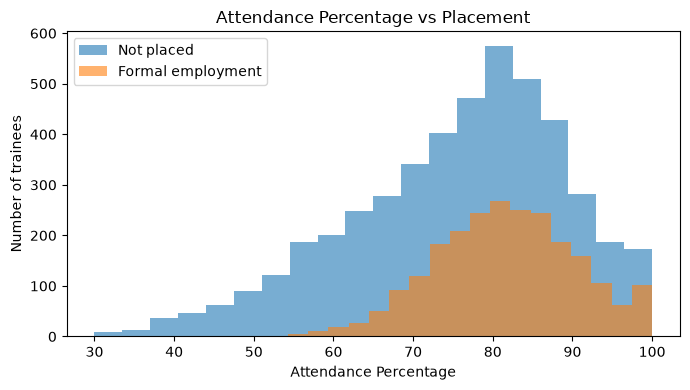

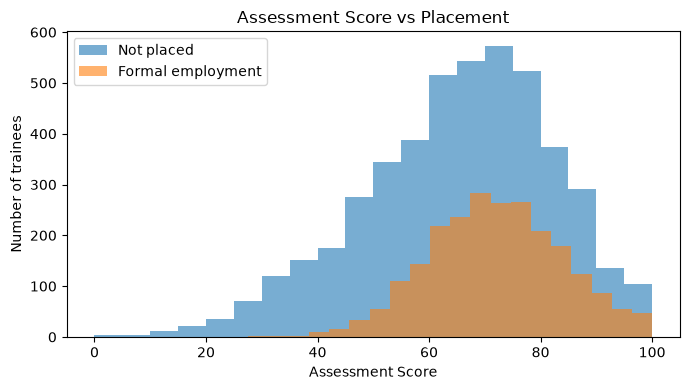

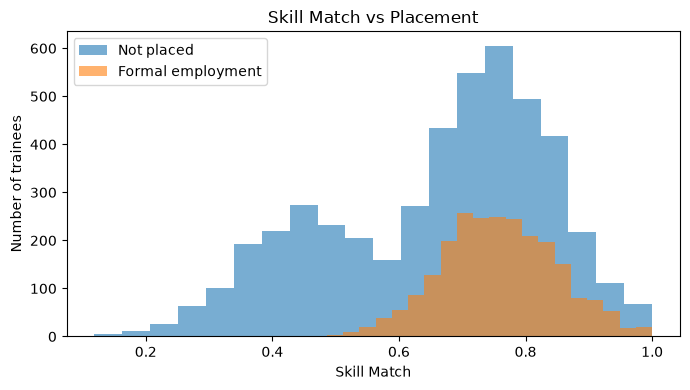

In [54]:
import matplotlib.pyplot as plt

features = [
    "attendance_percentage",
    "assessment_score",
    "skill_match"
]

for feature in features:
    plt.figure(figsize=(7, 4))

    ml_df[ml_df["placed"] == 0][feature].plot(
        kind="hist",
        bins=20,
        alpha=0.6,
        label="Not placed"
    )

    ml_df[ml_df["placed"] == 1][feature].plot(
        kind="hist",
        bins=20,
        alpha=0.6,
        label="Formal employment"
    )

    plt.title(f"{feature.replace('_', ' ').title()} vs Placement")
    plt.xlabel(feature.replace("_", " ").title())
    plt.ylabel("Number of trainees")
    plt.legend()
    plt.tight_layout()
    plt.show()

- Interpretation: All three features show better distributions for formally employed trainees, especially skill match and assessment score, indicating useful predictive signal.

- Conclusion: These features are promising for the placement model.

## 4.5 — Verify Predictive Signal

- Check whether attendance, assessment, and skill match actually have a strong relationship with formal employment before choosing the next model.

- Algorithm: Binned placement-rate analysis.

In [55]:
# Create feature ranges
ml_df["attendance_band"] = pd.cut(
    ml_df["attendance_percentage"],
    bins=[0, 60, 70, 80, 90, 100],
    labels=["<60", "60-70", "70-80", "80-90", "90-100"],
    include_lowest=True
)

ml_df["assessment_band"] = pd.cut(
    ml_df["assessment_score"],
    bins=[-1, 40, 60, 70, 80, 100],
    labels=["<40", "40-60", "60-70", "70-80", "80-100"],
    include_lowest=True
)

ml_df["skill_match_band"] = pd.cut(
    ml_df["skill_match"],
    bins=[0, 0.4, 0.6, 0.7, 0.8, 1.0],
    labels=["<0.4", "0.4-0.6", "0.6-0.7", "0.7-0.8", "0.8-1.0"],
    include_lowest=True
)

print("Formal employment rate by attendance:")
print(
    ml_df.groupby("attendance_band", observed=False)["placed"]
    .mean()
    .mul(100)
    .round(2)
)

print("\nFormal employment rate by assessment:")
print(
    ml_df.groupby("assessment_band", observed=False)["placed"]
    .mean()
    .mul(100)
    .round(2)
)

print("\nFormal employment rate by skill match:")
print(
    ml_df.groupby("skill_match_band", observed=False)["placed"]
    .mean()
    .mul(100)
    .round(2)
)

Formal employment rate by attendance:
attendance_band
<60        2.84
60-70     21.07
70-80     38.58
80-90     39.61
90-100    42.21
Name: placed, dtype: float64

Formal employment rate by assessment:
assessment_band
<40        1.42
40-60     23.42
60-70     38.31
70-80     39.61
80-100    39.74
Name: placed, dtype: float64

Formal employment rate by skill match:
skill_match_band
<0.4        0.00
0.4-0.6     7.84
0.6-0.7    38.93
0.7-0.8    43.20
0.8-1.0    41.30
Name: placed, dtype: float64


- Interpretation: Placement rises strongly with attendance and assessment up to a point, while skill match shows the clearest separation at lower levels.

- Conclusion: These features have real predictive signal and should remain in the placement model.

## 4.6 — Establish a Baseline

- Measure the accuracy of a simple “always predict not placed” model so we know whether our ML model is actually improving.

- Algorithm: Dummy Classifier baseline.

In [56]:
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, roc_auc_score

# Select target
y = ml_df["placed"]

# Use only the enriched features for now
baseline_features = [
    "district",
    "course_trade",
    "training_provider",
    "gender",
    "age",
    "attendance_percentage",
    "assessment_score",
    "certification_status",
    "skill_match",
    "previous_employment_status"
]

X = ml_df[baseline_features]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

baseline_model = DummyClassifier(
    strategy="most_frequent"
)

baseline_model.fit(X_train, y_train)

y_pred_baseline = baseline_model.predict(X_test)

print("Baseline Accuracy:", round(
    accuracy_score(y_test, y_pred_baseline), 4
))

print("Baseline ROC-AUC:", round(
    roc_auc_score(y_test, y_pred_baseline), 4
))

Baseline Accuracy: 0.6657
Baseline ROC-AUC: 0.5


## 4.7 — Train Enriched Placement Model

- Train the placement model using the richer ML dataset and compare it against the baseline.

- Algorithm: Logistic Regression + One-Hot Encoding + StandardScaler.

In [57]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

categorical_features = [
    "district",
    "course_trade",
    "training_provider",
    "gender",
    "certification_status",
    "previous_employment_status"
]

numeric_features = [
    "age",
    "attendance_percentage",
    "assessment_score",
    "skill_match"
]

preprocessor_enriched = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numeric",
            StandardScaler(),
            numeric_features
        )
    ]
)

enriched_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor_enriched),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

enriched_model.fit(X_train, y_train)

print("Enriched placement model trained successfully.")

Enriched placement model trained successfully.


In [58]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

y_pred_enriched = enriched_model.predict(X_test)
y_prob_enriched = enriched_model.predict_proba(X_test)[:, 1]

print("Enriched Placement Model Evaluation")
print(f"Accuracy : {accuracy_score(y_test, y_pred_enriched):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_enriched):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred_enriched):.4f}")
print(f"F1 Score : {f1_score(y_test, y_pred_enriched):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_test, y_prob_enriched):.4f}")

print("\nBaseline Accuracy: 0.6657")

Enriched Placement Model Evaluation
Accuracy : 0.6586
Precision: 0.4725
Recall   : 0.1838
F1 Score : 0.2646
ROC-AUC  : 0.6598

Baseline Accuracy: 0.6657


In [59]:
features_to_check = [
    "attendance_percentage",
    "assessment_score",
    "skill_match",
    "previous_employment_status",
    "certification_status"
]

for feature in features_to_check:
    print("\n" + "=" * 60)
    print(feature)

    if ml_df[feature].dtype == "object":
        result = (
            ml_df.groupby(feature)["placed"]
            .mean()
            .mul(100)
            .sort_values(ascending=False)
        )
    else:
        result = (
            ml_df.groupby(
                pd.qcut(
                    ml_df[feature],
                    q=5,
                    duplicates="drop"
                )
            )["placed"]
            .mean()
            .mul(100)
        )

    print(result.round(2))


attendance_percentage
attendance_percentage
(29.999, 68.0]    10.64
(68.0, 76.3]      36.16
(76.3, 82.0]      39.27
(82.0, 87.82]     39.83
(87.82, 100.0]    41.21
Name: placed, dtype: float64

assessment_score
assessment_score
(-0.001, 55.2]    12.44
(55.2, 65.2]      35.09
(65.2, 72.5]      40.40
(72.5, 80.6]      39.87
(80.6, 100.0]     39.44
Name: placed, dtype: float64

skill_match
skill_match
(0.118, 0.572]     2.63
(0.572, 0.695]    37.65
(0.695, 0.757]    43.86
(0.757, 0.823]    42.11
(0.823, 1.0]      40.97
Name: placed, dtype: float64

previous_employment_status


TypeError: unsupported operand type(s) for -: 'str' and 'str'

In [1]:
from pathlib import Path
import pandas as pd

files = [
    Path("../../datafile.xls"),
    Path("../../datafile (1).xls"),
    Path("../../RS_Session_265_AU_1878_D_3_i.csv")
]

for file in files:
    print("\n" + "=" * 70)
    print(file.name)
    print("=" * 70)

    if file.suffix.lower() == ".xls":
        df = pd.read_excel(file)
    else:
        df = pd.read_csv(file)

    print("Shape:", df.shape)
    print("\nColumns:")
    print(df.columns.tolist())

    print("\nFirst 5 rows:")
    display(df.head())


datafile.xls


FileNotFoundError: [Errno 2] No such file or directory: '..\\..\\datafile.xls'